# Image Generation

In [ ]:
import requests
import time

# --- Your StarryAI API Key ---
API_KEY = "YOUR API KEY"

# --- Request headers ---
headers = {
    "accept": "application/json",
    "content-type": "application/json",
    "X-API-Key": API_KEY
}

# --- Step 1: Submit image creation request ---
create_url = "https://api.starryai.com/creations/"

payload = {
    "prompt": "A futuristic iguana on the beach in pointillism style",
    "model": "lyra",
    "aspectRatio": "square",
    "highResolution": False,
    "images": 1,
    "steps": 20,
    "initialImageMode": "color"
}

print("🔁 Sending image generation request...")

response = requests.post(create_url, json=payload, headers=headers)
response.raise_for_status()
data = response.json()

creation_id = data.get("id")
if not creation_id:
    raise Exception("❌ No creation ID returned. Something went wrong.")
print(f"✅ Creation request accepted! Creation ID: {creation_id}")

# --- Step 2: Poll for image generation status ---
poll_url = f"https://api.starryai.com/creations/{creation_id}"
image_url = None

print("⏳ Waiting for image to be generated...")

while True:
    poll_response = requests.get(poll_url, headers=headers)
    poll_data = poll_response.json()

    status = poll_data.get("status")
    print(f"🔄 Status: {status}")

    if status == "completed":
        images = poll_data.get("images", [])
        if images and images[0].get("url"):
            image_url = images[0]["url"]
            print(f"\n✅ Image generation complete!\nImage URL: {image_url}")
            break
        else:
            print("⚠️ Image completed, but no URL found.")
            break
    elif status in ["failed", "cancelled"]:
        print(f"❌ Image generation {status}.")
        break
    else:
        time.sleep(5)


🔁 Sending image generation request...
✅ Creation request accepted! Creation ID: 139643
⏳ Waiting for image to be generated...
🔄 Status: submitted
🔄 Status: in progress
🔄 Status: completed

✅ Image generation complete!
Image URL: https://tmp.starryai.com/api/139643/cda4c08e-ffd4-45ab-9269-e57a422640e6.png


# BACKGROUND REMOVAL

In [ ]:
# ✅ Step 1: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install rembg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.7/54.7 kB 3.4 MB/s eta 0:00:00


In [ ]:
!pip install onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 83.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 6.7 MB/s eta 0:00:00


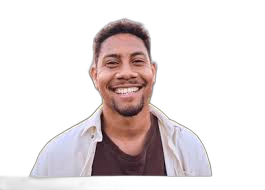

In [ ]:
from rembg import remove
from PIL import Image
import io

input_path = '/content/drive/MyDrive/download.jpeg'
output_path = '/content/drive/MyDrive/output.png'


with open(input_path, 'rb') as inp_file:
    input_bytes = inp_file.read()
    output_bytes = remove(input_bytes)


with open(output_path, 'wb') as out_file:
    out_file.write(output_bytes)

# Display the result
display(Image.open(output_path))


#IMAGE ENHANCER

# Text Repharase

In [ ]:
import requests
from pprint import pprint

key = 'Sapling API KEY'
url = 'https://api.sapling.ai/api/v1/rephrase'

data = {
    'key': key,
    'text': 'hey wuts going on',
    'mapping':'informal_to_formal'
}

try:
    response = requests.post(url, json=data)
    if 200 <= response.status_code < 300:
      resp_json = response.json()
      results = resp_json['results']
      pprint(results)
    else:
      print('Error: ', str(response.status_code), response.text)
except Exception as e:
    print('Error: ', e)

[{'hash': '6fc2ea79-0e1e-5ed8-8095-798f42e4d5f3',
  'model_version': 'v20241219',
  'original': 'hey wuts going on',
  'rephrase_type': 'informal_to_formal',
  'replacement': 'What is happening?'}]


In [ ]:
pip install docx

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for docx: filename=docx-0.2.4-py3-none-any.whl size=53893 sha256=2395145aa4ef7be1789857ea5224bac25bf35546dc80ab4da4b4674e72764f6b
  Stored in directory: /root/.cache/pip/wheels/c1/3e/c3/e81c11effd0be5658a035947c66792dd993bcff317eae0e1ed
Successfully built docx


In [ ]:
pip install docx2txt requests python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 4.0 MB/s eta 0:00:00


In [ ]:
import requests
import docx2txt
from docx import Document
from time import sleep

# CONFIG
API_KEY = 'SApling API KEY'
INPUT_DOCX = 'Input docx path'
OUTPUT_DOCX = 'Output path to save file'
MAPPING_TYPE = 'informal_to_formal'

# Load raw text from DOCX
raw_text = docx2txt.process(INPUT_DOCX)

# Split text into paragraphs (can be modified to use sentences)
paragraphs = raw_text.split('\n')

# Create output doc
new_doc = Document()

def rephrase_text(text, key, mapping):
    if not text.strip():
        return text  # Skip blank lines
    url = 'https://api.sapling.ai/api/v1/rephrase'
    data = {
        'key': key,
        'text': text,
        'mapping': mapping
    }
    try:
        response = requests.post(url, json=data)
        if 200 <= response.status_code < 300:
            results = response.json().get('results', [])
            if results and 'replacement' in results[0]:
                return results[0]['replacement']
    except Exception as e:
        print("Error rephrasing:", e)
    return text


# Process each paragraph
for para in paragraphs:
    rephrased = rephrase_text(para, API_KEY, MAPPING_TYPE)
    new_doc.add_paragraph(rephrased)
    sleep(1)  # Avoid rate limits

# Save output
new_doc.save(OUTPUT_DOCX)
print(f"✅ Rephrased document saved as: {OUTPUT_DOCX}")


✅ Rephrased document saved as: /content/drive/MyDrive/output.docx


# AI HUMANIZER

In [ ]:
!pip install -q transformers sentencepiece

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

model_name = "humarin/chatgpt_paraphraser_on_T5_base"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to("cuda" if torch.cuda.is_available() else "cpu")


tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/892M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/892M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

In [ ]:
def humanize_text(text, num_return_sequences=1):
    input_text = f"paraphrase: {text} </s>"
    inputs = tokenizer(input_text, return_tensors="pt", truncation=True, max_length=256).to(model.device)

    outputs = model.generate(
        **inputs,
        max_length=256,
        num_beams=5,
        num_return_sequences=num_return_sequences,
        temperature=0.7,
        no_repeat_ngram_size=2,
    )

    return [tokenizer.decode(o, skip_special_tokens=True) for o in outputs]


In [ ]:
ai_text = "The utilization of artificial intelligence in industry has increased drastically."
results = humanize_text(ai_text, num_return_sequences=3)
for idx, res in enumerate(results, 1):
    print(f"{idx}: {res}")

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


1: There has been a significant increase in the application of artificial intelligence in industry.
2: There has been a significant increase in the application of artificial intelligence to industry.
3: The use of artificial intelligence in industry has experienced a significant surge.
